In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from keras.models import Sequential
from keras.layers import Dense,Input


In [2]:
df = pd.read_csv('data.csv')
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [3]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:
df.drop(['id','Unnamed: 32'],axis=1,inplace=True)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

In [6]:
#Split Features and Labels
X = df.drop('diagnosis',axis=1)
Y = df['diagnosis']

In [7]:
Y_diagnosis = ({'B':0,'M':1})
Y = Y.map(Y_diagnosis)

In [8]:
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [9]:
X_train.shape

(455, 30)

In [10]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [11]:
model=Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(32,activation='relu'),
    Dense(16,activation='relu'),
    Dense(1,activation='sigmoid')
])

In [12]:
model.compile(
    optimizer='adam',
    loss ='binary_crossentropy',
    metrics =['accuracy']
)

In [13]:
history = model.fit(X_train,Y_train,epochs=10,batch_size=32,validation_split=0.1)

Epoch 1/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.6870 - loss: 0.5855 - val_accuracy: 0.8696 - val_loss: 0.4173
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8582 - loss: 0.4124 - val_accuracy: 0.8696 - val_loss: 0.3131
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9267 - loss: 0.3176 - val_accuracy: 0.9348 - val_loss: 0.2516
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9413 - loss: 0.2540 - val_accuracy: 0.9783 - val_loss: 0.2112
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9560 - loss: 0.2105 - val_accuracy: 0.9783 - val_loss: 0.1822
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9609 - loss: 0.1779 - val_accuracy: 0.9783 - val_loss: 0.1604
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9707 - loss: 0.1505 - val_accuracy: 0.9565 - val_loss: 0.1432
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9731 - loss: 0.1287 - val_accuracy: 0.9565 - v

In [14]:
model.evaluate(X_test,Y_test)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9825 - loss: 0.0872


[0.08723469823598862, 0.9824561476707458]

In [15]:
pred_probability = model.predict(X_test)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


In [16]:
predictions = (pred_probability>0.5).astype(int)

In [17]:
accuracy = accuracy_score(Y_test,predictions)
accuracy

0.9824561403508771

In [18]:
history.history

{'accuracy': [0.6870415806770325,
  0.8581907153129578,
  0.92665034532547,
  0.9413203001022339,
  0.955990195274353,
  0.9608802199363708,
  0.9706601500511169,
  0.9731051325798035,
  0.9779950976371765,
  0.9779950976371765],
 'loss': [0.5854641795158386,
  0.41244423389434814,
  0.317603200674057,
  0.2540219724178314,
  0.21048632264137268,
  0.17791305482387543,
  0.15052761137485504,
  0.12865912914276123,
  0.11142430454492569,
  0.09700893610715866],
 'val_accuracy': [0.8695651888847351,
  0.8695651888847351,
  0.9347826242446899,
  0.97826087474823,
  0.97826087474823,
  0.97826087474823,
  0.95652174949646,
  0.95652174949646,
  0.95652174949646,
  0.95652174949646],
 'val_loss': [0.41733962297439575,
  0.31314757466316223,
  0.25156188011169434,
  0.21124637126922607,
  0.18218640983104706,
  0.16038787364959717,
  0.1432105004787445,
  0.12962044775485992,
  0.1179891973733902,
  0.1099545881152153]}

In [19]:
cm = confusion_matrix(Y_test,predictions)
cm

array([[71,  0],
       [ 2, 41]])

In [20]:
cm_df = pd.DataFrame(cm,index=['Actual Benign','Actual Malignant'],columns=['Predicted Benign','Predicted Malignant'])

In [21]:
cm_df

,Predicted Benign,Predicted Malignant
Actual Benign,71,0
Actual Malignant,2,41


Text(0.5, 1.0, 'Artificial Neural Network')

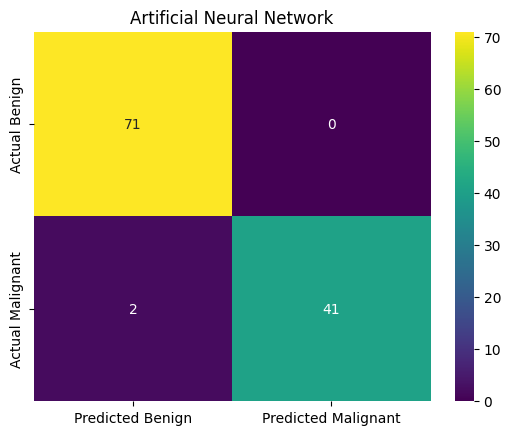

In [22]:
sns.heatmap(cm_df,annot=True,fmt='d',cmap='viridis')
plt.title("Artificial Neural Network")

In [23]:
cf = classification_report(Y_test,predictions,output_dict=True)
cf_df = pd.DataFrame(cf).transpose()
cf_df

,precision,recall,f1-score,support
0,0.972603,1.000000,0.986111,71.000000
1,1.000000,0.953488,0.976190,43.000000
accuracy,0.982456,0.982456,0.982456,0.982456
macro avg,0.986301,0.976744,0.981151,114.000000
weighted avg,0.982937,0.982456,0.982369,114.000000


In [24]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train,Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [25]:
lr_pred = lr.predict(X_test)

In [26]:
lr_accuracy = accuracy_score(Y_test,lr_pred)
lr_accuracy

0.9736842105263158

In [27]:
cm2 = confusion_matrix(Y_test,lr_pred)
cm2

array([[70,  1],
       [ 2, 41]])

In [28]:
cm2_df = pd.DataFrame(cm2,index=['Actual Benign','Actual Malignant'],columns=['Predicted Benign','Predicted Malignant'])

Text(0.5, 1.0, 'Logistic Regression')

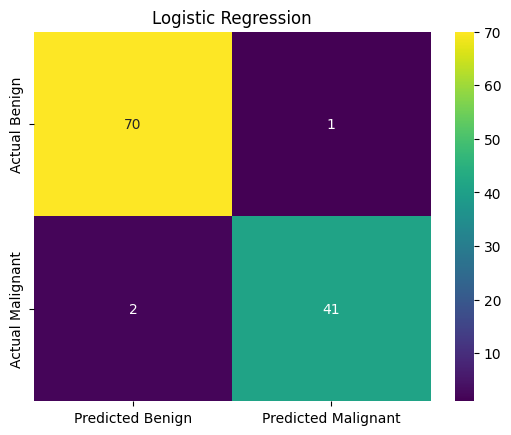

In [29]:
sns.heatmap(cm2_df,annot=True,fmt='d',cmap='viridis')
plt.title("Logistic Regression")

In [32]:
cf2 = classification_report(Y_test,lr_pred,output_dict=True)
cf2_df = pd.DataFrame(cf2).transpose()
cf2_df

,precision,recall,f1-score,support
0,0.972222,0.985915,0.979021,71.000000
1,0.976190,0.953488,0.964706,43.000000
accuracy,0.973684,0.973684,0.973684,0.973684
macro avg,0.974206,0.969702,0.971863,114.000000
weighted avg,0.973719,0.973684,0.973621,114.000000
